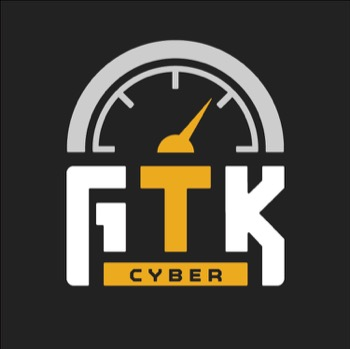

# Worksheet 4.1: DGA Detection using Machine Learning
 
This worksheet covers concepts covered in Module 4 - Supervised Learning. Train and evaluate a classification model using [sklearn](http://scikit-learn.org/stable/). It should take no more than 40-60 minutes to complete.  Please raise your hand if you get stuck.

This notebook is a step-by-step guide on how to detect domains that were generated using "Domain Generation Algorithm" (DGA). We will walk you through the process of creating a decision tree classifier which you will use to determine whether a given domain is legit or not. Once you have implemented the classifier, the worksheet will walk you through evaluating your model and getting interpretable results for predictions.


1. **Feature Engineering** - Completed in Module 3
2. **Machine Learning Classification** - predict whether a domain is legit or not using a Decision Tree Classifier

## Import the Libraries
For this exercise, we will be using:
* Pandas (http://pandas.pydata.org/pandas-docs/stable/)
* Numpy (https://docs.scipy.org/doc/numpy/reference/)
* Matplotlib (http://matplotlib.org/api/pyplot_api.html)
* Scikit-learn (http://scikit-learn.org/stable/documentation.html)
* Lime (https://github.com/marcotcr/lime)
* SHAP (https://shap.readthedocs.io/en/latest/index.html)

In [ ]:
# --- data-loader (local files / Databricks volume) ---
import os
import tempfile
try:
    dbutils  # defined only on Databricks
    DATA_HOME = os.environ.get("COURSE_DATA_HOME", "/Volumes/ai_cyber_bootcamp/course/data/")
    WORK_HOME = os.path.abspath("../work") + "/"
    SCRATCH_HOME = tempfile.gettempdir()
    ON_DATABRICKS = True
except NameError:
    DATA_HOME = "../data/"
    WORK_HOME = DATA_HOME
    SCRATCH_HOME = WORK_HOME
    ON_DATABRICKS = False
os.makedirs(WORK_HOME, exist_ok=True)

def handoff(name):
    """Output of an earlier worksheet: the student's own copy if it exists, else the shipped one."""
    p = WORK_HOME + name
    return p if os.path.exists(p) else DATA_HOME + name
# --- end data-loader ---


In [ ]:
# Load Libraries - Make sure to run this cell!
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import tree, model_selection, metrics
from sklearn.inspection import permutation_importance
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn import svm

import lime.lime_tabular
import shap
import io
import pickle
import warnings
warnings.filterwarnings('ignore')

In [ ]:
# DATA_HOME comes from the data-loader cell at the top of this notebook
shap.initjs()

## Load Features and Labels

If you got stuck in the Feature Engineering section, please simply uncomment the code below to load the feature matrix we prepared for you, so you can move on to train a Decision Tree Classifier.

In [ ]:
#load full dataset
df_final = pd.read_csv(handoff('dga_features_final_df.csv'))

#If you didn't get a working dataset from module 4, uncomment the line below
#df_final = pd.read_csv(DATA_HOME + 'our_data_dga_features_final_df.csv')

df_final.head()

In [ ]:
print(df_final['isDGA'].value_counts())

## Prepare the ```feature_matrix``` and ```target``` 

- In statistics and machine learning, the ```feature_matrix``` is often referred to as ```X```
- The target vector that contains the labels for each row is called ```y``` 
- In sklearn both the features and targets can either be a pandas DataFrame/Series or numpy array/vector respectively (can't be lists!)

Tasks:
- Create a vector that contains the **target**s
- Create the **feature_matrix** that has only the features and not the targets 

## Create a vector named 'target' 

Assign the **isDGA** column to a pandas Series named **target**. The ```target``` variable should be a vector (1 dimension) of the correct (ground truth) answer for each row of the dataset. For this DGA use case, each item will be a string that indicates whether the domain was **dga** or **legit**. 

In [ ]:
target =

## Create the Feature Matrix

In order to train a model you have to separate the features from the targets. Create the ```feature_matrix``` (pandas dataframe) by dropping the **isDGA** column from ```df_final```.

In [ ]:
feature_matrix =

Creata a list of our feature names for plotting later and if we need to pull the features again from the full dataframe.


In [ ]:
feature_names =

# Test-Train split

Split (the dataset) your ```feature_matrix``` and ```target``` into **train** and **test** subsets using sklearn [model_selection.train_test_split](http://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html)

Output of the split should be 2 complete sets of data (**train** and **test** that are still separated into features and labels: 
 - **feature_matrix_train**: 75% of the feature matrix (data)
 - **feature_matrix_test**: the remaining 25% of the feature matrix
 - **target_train**: the labels for the train features
 - **target_test**: the labels for the test features

In [ ]:
feature_matrix_train, feature_matrix_test, target_train, target_test =

# Train the model and make a prediction

Finally, we have prepared and split the data. Let's start classifying!!   

Tasks:
-  Use the sklearn [tree.DecisionTreeClassifier()](http://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html), instantiate (create) a decision tree model with default parameters (we will tune these in the next lab).
- Train this model using the ```feature_matrix_train``` and ```target_train``` data (you will need to call the **.fit()** method on the model to do this).
-  Next, pull a few random rows from the data to spot check the predictions of the model against the true labels.

In [ ]:
# Your code here...

That's it! You trained the model. Now extract a row from the test set to see if the model can predict the correct answer by comparing it to the test target (ground truth). 

In [ ]:
# Extract a row from the test data
row_number = 14
row_feature = feature_matrix_test[row_number:row_number+1]

# Make the prediction
row_pred = d_tree_model.predict(row_feature)

# pull out the ground truth for this row
row_target = target_test[row_number:row_number+1]
                                                    
# print the results and the ground truth
print('Predicted class:', row_pred)
print('Ground truth class:', row_target)
print('Accurate prediction?', row_pred == row_target)

# Make predictions on test set

Make predictions for all your **test** data. This will be data that the model has not 'seen' before so we will use these predictions to evaluate how well the model can predict the correct answer on new data by calling a few different metrics functions.

- Call the ```.predict()``` method on the model ```d_tree_model``` with your test data ```feature_matrix_test``` and store the results in a variable called ```test_predictions```. 
  
- Then calculate the **accuracy** (and several other metrics) using ```target_test``` (which are the true labels/ground truth) AND your models predictions on the test portion ```test_predictions``` as inputs.

In [ ]:
# make predictions on all of the test data
test_predictions =

# print a sample of the predictions
print(test_predictions[0:5])

#### Save the model as a pickle file

In [ ]:
# The bootcamp-labs cluster can't write to the workspace ../work folder (WORK_HOME): the write fails
# asynchronously with AsyncFlushFailedException. Save to local scratch space instead; later
# worksheets load the model via handoff(), which falls back to the copy shipped in DATA_HOME.
filename = os.path.join(SCRATCH_HOME, 'dga_decision_tree.pkl')
with open(filename, 'wb') as f:
    pickle.dump(d_tree_model, f)


# Evaluate the model performance with metrics and visualizations

## Print metrics
Use sklearn [metrics.accuracy_score](http://scikit-learn.org/stable/modules/generated/sklearn.metrics.accuracy_score.html) to calculate the model accuracy.

In [ ]:
# Your code here...

## (Optional) Visualizing your Tree
As an optional step, you can actually visualize your tree.  The following code will generate a graph of your decision tree.  You can also use tools like graphviz (http://www.graphviz.org) and pydotplus (or pydot) too.

In [ ]:
# Optional Imports for visualizing the Decision Trees.
from sklearn import tree
import matplotlib.pyplot as plt

In [ ]:
plt.figure(figsize=(20, 10))
tree.plot_tree(d_tree_model,
               feature_names=feature_names,
               filled=True,
               rounded=True,
               fontsize=3)

plt.show()

# Explain a model
Two methods for explaining a model. 

## Method 1: feature importance - impurity decrease

In SciKit Learn tree (and other) models, feature importances are provided by the fitted attribute `feature_importances_` and they are computed as the mean and standard deviation of accumulation of the impurity decrease within each tree.


In [ ]:
importances = d_tree_model.feature_importances_

d_tree_importances = pd.Series(importances, index=feature_names)

fig, ax = plt.subplots()
d_tree_importances.plot.barh(ax=ax)
ax.set_title("Feature importances using MDI")
ax.set_ylabel("Mean decrease in impurity")
fig.tight_layout()

## Method 2: Feature Importance using feature permutation

Permutation feature importance overcomes limitations of the impurity-based feature importance: they do not have a bias toward high-cardinality features and can be computed on a left-out test set.


In [ ]:
result = permutation_importance(
    d_tree_model, feature_matrix_test, target_test, n_repeats=10, random_state=42, n_jobs=2
)

perm_importances = pd.Series(result.importances_mean, index=feature_names)

In [ ]:
fig, ax = plt.subplots()
perm_importances.plot.barh(yerr=result.importances_std, ax=ax)
ax.set_title("Feature importances using permutation on full model")
ax.set_ylabel("Mean accuracy decrease")
fig.tight_layout()

## Method 3: SHAP



In [ ]:
# explain all the predictions in the test set
explainer = shap.KernelExplainer(d_tree_model.predict_proba, feature_matrix_train)
shap_values = explainer.shap_values(feature_matrix_test)
shap.force_plot(explainer.expected_value[0], shap_values[..., 0], feature_matrix_test)

# Explaining a specific prediction: SHAP
In the example below, you can use SHAP to explain how a classifier arrived at its prediction.  Try running SHAP with the  classifier you've created and various rows to see how it functions. 

In [ ]:
# choose an item from the test set and print the values
sample_number = 20
print('true_label =', target_test.iloc[sample_number])
feature_matrix_test.iloc[sample_number]

In [ ]:
# explain the model's prediction on the sample we just printed above using shap

explainer = shap.KernelExplainer(d_tree_model.predict_proba, feature_matrix_train)
shap_values = explainer.shap_values(feature_matrix_test.iloc[sample_number])
shap.force_plot(explainer.expected_value[0], shap_values[:, 0], feature_matrix_test.iloc[sample_number])

### Explain a prediction: LIME
Lime is similar to SHAP in that it can help us understand what features were used/influencial in the decision of a prediction. 

In [ ]:
explainer = lime.lime_tabular.LimeTabularExplainer(feature_matrix_train, 
                                                   feature_names=feature_names, 
                                                  class_names=d_tree_model.classes_, 
                                                   discretize_continuous=False)

Let's look at the explanation for one data point (row) from the test set. 

Now we will call the explainer on this sample to see what the model was using to get its prediction

In [ ]:
exp = explainer.explain_instance(feature_matrix_test.iloc[sample_number], 
                                 d_tree_model.predict_proba, 
                                 num_features=6)
exp.as_list()

In [ ]:
fig = exp.as_pyplot_figure()
display(fig)
plt.close(fig)

#  Train and evaluate more models
Now that you've built a Decision Tree, let's try out two other classifiers and see how they perform on this data.  For this next exercise, create classifiers using:

* Support Vector Machine
* Random Forest
* K-Nearest Neighbors (http://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html)  

Once you've done that, run the various performance metrics to determine which classifier works best.

## Create the Random Forest Classifier

In [ ]:
random_forest_clf =

#### Make predictions

In [ ]:
random_forest_test_predictions =

#### Metrics

In [ ]:
# Your code here...

### Feature Importance

In [ ]:
importances = random_forest_clf.feature_importances_

forest_importances = pd.Series(importances, index=feature_names)

fig, ax = plt.subplots()
forest_importances.plot.barh(ax=ax)
ax.set_title("Feature importances using MDI")
ax.set_ylabel("Mean decrease in impurity")
fig.tight_layout()

In [ ]:
rf_result = permutation_importance(
    random_forest_clf, feature_matrix_test, target_test, n_repeats=10, random_state=42, n_jobs=2
)

rf_importances = pd.Series(rf_result.importances_mean, index=feature_names)

In [ ]:
fig, ax = plt.subplots()
rf_importances.plot.barh(yerr=rf_result.importances_std, ax=ax)
ax.set_title("Feature importances using permutation on full model")
ax.set_ylabel("Mean accuracy decrease")
fig.tight_layout()

## Train a SVM classifier


In [ ]:
svm_classifier =

#### Make predictions on the test set

In [ ]:
svm_test_predictions =

#### Metrics

In [ ]:
 # Your code here...

## Train a K-Nearest Neighbors Classifier

In [ ]:
knn_clf =

#### Make predictions

In [ ]:
# Your code here ...

#### Metrics

In [ ]:
print("KNN Accuracy:", metrics.accuracy_score(target_test, knn_test_predictions))

In [ ]:
print(metrics.classification_report(target_test, knn_test_predictions))

In [ ]:
knn_conf_matrix = metrics.confusion_matrix(target_test, knn_test_predictions, labels=knn_clf.classes_)
disp = metrics.ConfusionMatrixDisplay(confusion_matrix=knn_conf_matrix,
                                       display_labels=knn_clf.classes_)

disp.plot(cmap='ocean');